# AI-Based Workplace Burnout Detection System

## Machine Learning Pipeline Notebook

This notebook documents the complete machine learning implementation for the MSc project.

It includes:

- Dataset loading
- Data inspection
- Target creation
- Leakage removal
- Dataset resizing to 50k
- Train-test split
- One-Hot Encoding
- SMOTE
- Random Forest
- XGBoost
- Model comparison
- SHAP explainability
- Feature engineering experiment

## 1. Import Libraries

In [2]:
import os
import pandas as pd
import numpy as np

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from joblib import dump, load
import shap

In [3]:
print("nootbook is working")

nootbook is working


## 2. Load Dataset

In [4]:
DATA_PATH = "../data/tech_mental_health_burnout.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully
Shape: (150000, 25)


,age,gender,job_role,experience_years,company_size,work_mode,work_hours_per_week,overtime_hours,meetings_per_day,deadlines_missed,...,screen_time_hours,caffeine_intake,social_support_score,has_therapy,stress_level,anxiety_score,depression_score,burnout_score,burnout_level,seeks_professional_help
0,50,Female,Backend Developer,7.8,Large,Hybrid,45.0,0.0,5.0,0,...,8.6,1,4.4,0,4.8,4.3,2.6,1.0,Low,0
1,36,Male,Frontend Developer,1.8,Mid-size,Remote,56.0,4.0,6.0,0,...,11.5,4,4.1,0,6.7,4.8,4.6,3.7,Moderate,0
2,29,Male,DevOps,2.5,MNC,Hybrid,43.0,2.0,6.0,3,...,6.8,3,6.5,0,4.5,4.0,2.5,1.0,Low,0
3,42,Female,Backend Developer,1.5,Mid-size,Hybrid,57.0,9.0,4.0,1,...,10.2,5,2.5,0,6.1,5.8,1.8,3.6,Moderate,0
4,40,Female,Frontend Developer,3.4,Large,Remote,49.0,0.0,3.0,4,...,11.9,5,4.6,0,7.2,5.9,2.4,3.5,Low,0


In [5]:
print("hello baby")

hello baby


## 3. Dataset Inspection

In [6]:
print("Columns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["burnout_level"].value_counts())

Columns:
['age', 'gender', 'job_role', 'experience_years', 'company_size', 'work_mode', 'work_hours_per_week', 'overtime_hours', 'meetings_per_day', 'deadlines_missed', 'job_satisfaction', 'manager_support', 'work_life_balance', 'sleep_hours', 'physical_activity_days', 'screen_time_hours', 'caffeine_intake', 'social_support_score', 'has_therapy', 'stress_level', 'anxiety_score', 'depression_score', 'burnout_score', 'burnout_level', 'seeks_professional_help']

Data Types:
age                          int64
gender                         str
job_role                       str
experience_years           float64
company_size                   str
work_mode                      str
work_hours_per_week        float64
overtime_hours             float64
meetings_per_day           float64
deadlines_missed             int64
job_satisfaction           float64
manager_support            float64
work_life_balance          float64
sleep_hours                float64
physical_activity_days       int64

## 4. Preprocessing

The original target variable was `burnout_level`.

It was converted into binary classification:

- `Low` = 0
- `Moderate` and `High` = 1

Leakage columns removed:

- `burnout_level`
- `burnout_score`

In [7]:
df_cleaned = df.copy()

df_cleaned = df_cleaned.drop_duplicates()

df_cleaned["target"] = df_cleaned["burnout_level"].apply(
    lambda x: 0 if x == "Low" else 1
)

df_cleaned = df_cleaned.drop(columns=["burnout_level", "burnout_score"])

print("Cleaned shape:", df_cleaned.shape)
print(df_cleaned["target"].value_counts())

os.makedirs("../outputs", exist_ok=True)
df_cleaned.to_csv("../outputs/cleaned_dataset.csv", index=False)

Cleaned shape: (150000, 24)
target
0    131620
1     18380
Name: count, dtype: int64


## 5. Resize Dataset to 50,000 Rows Using Stratified Sampling

In [8]:
df_50k, _ = train_test_split(
    df_cleaned,
    train_size=50000,
    stratify=df_cleaned["target"],
    random_state=42
)

df_50k = df_50k.reset_index(drop=True)

print("Resized shape:", df_50k.shape)
print(df_50k["target"].value_counts())

df_50k.to_csv("../outputs/resized_50k_dataset.csv", index=False)

Resized shape: (50000, 24)
target
0    43873
1     6127
Name: count, dtype: int64


## 6. Train-Test Split

In [9]:
X = df_50k.drop(columns=["target"])
y = df_50k["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\nTrain Distribution:")
print(y_train.value_counts())
print("\nTest Distribution:")
print(y_test.value_counts())

X_train: (40000, 23)
X_test: (10000, 23)

Train Distribution:
target
0    35098
1     4902
Name: count, dtype: int64

Test Distribution:
target
0    8775
1    1225
Name: count, dtype: int64


## 7. One-Hot Encoding

In [10]:
categorical_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()
print("Categorical columns:", categorical_cols)

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_encoded_array = encoder.fit_transform(X_train[categorical_cols])
X_test_encoded_array = encoder.transform(X_test[categorical_cols])

encoded_cols = encoder.get_feature_names_out(categorical_cols)

X_train_encoded_df = pd.DataFrame(X_train_encoded_array, columns=encoded_cols, index=X_train.index)
X_test_encoded_df = pd.DataFrame(X_test_encoded_array, columns=encoded_cols, index=X_test.index)

X_train_num = X_train.drop(columns=categorical_cols)
X_test_num = X_test.drop(columns=categorical_cols)

X_train_encoded = pd.concat([X_train_num, X_train_encoded_df], axis=1)
X_test_encoded = pd.concat([X_test_num, X_test_encoded_df], axis=1)

print("Encoded train shape:", X_train_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)

os.makedirs("../models", exist_ok=True)
dump(encoder, "../models/onehot_encoder.joblib")

Categorical columns: ['gender', 'job_role', 'company_size', 'work_mode']
Encoded train shape: (40000, 37)
Encoded test shape: (10000, 37)


['../models/onehot_encoder.joblib']

## 8. SMOTE Applied Only to Training Data

In [11]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_encoded, y_train)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE:
target
0    35098
1     4902
Name: count, dtype: int64

After SMOTE:
target
0    35098
1    35098
Name: count, dtype: int64


## 9. Random Forest Model

In [12]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

rf_cv = cross_validate(
    rf_model,
    X_train_smote,
    y_train_smote,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest CV Results")
print("Accuracy:", rf_cv["test_accuracy"].mean())
print("Precision:", rf_cv["test_precision"].mean())
print("Recall:", rf_cv["test_recall"].mean())
print("F1:", rf_cv["test_f1"].mean())
print("ROC-AUC:", rf_cv["test_roc_auc"].mean())

rf_model.fit(X_train_smote, y_train_smote)

rf_pred = rf_model.predict(X_test_encoded)
rf_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1 Score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_prob)
}

rf_results

Random Forest CV Results
Accuracy: 0.9613368376129257
Precision: 0.9593217113296063
Recall: 0.963530770570235
F1: 0.9614209714424871
ROC-AUC: 0.9949824154910647


{'Model': 'Random Forest',
 'Accuracy': 0.9243,
 'Precision': 0.7,
 'Recall': 0.6685714285714286,
 'F1 Score': 0.6839248434237996,
 'ROC-AUC': 0.9513073550787836}

## 10. XGBoost Model

In [13]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_cv = cross_validate(
    xgb_model,
    X_train_smote,
    y_train_smote,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("XGBoost CV Results")
print("Accuracy:", xgb_cv["test_accuracy"].mean())
print("Precision:", xgb_cv["test_precision"].mean())
print("Recall:", xgb_cv["test_recall"].mean())
print("F1:", xgb_cv["test_f1"].mean())
print("ROC-AUC:", xgb_cv["test_roc_auc"].mean())

xgb_model.fit(X_train_smote, y_train_smote)

xgb_pred = xgb_model.predict(X_test_encoded)
xgb_prob = xgb_model.predict_proba(X_test_encoded)[:, 1]

xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1 Score": f1_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_prob)
}

xgb_results

XGBoost CV Results
Accuracy: 0.958430688300337
Precision: 0.9590081113633999
Recall: 0.9578039663607409
F1: 0.9584040275985835
ROC-AUC: 0.9941437382428369


{'Model': 'XGBoost',
 'Accuracy': 0.9244,
 'Precision': 0.6895715440582053,
 'Recall': 0.6963265306122449,
 'F1 Score': 0.6929325751421609,
 'ROC-AUC': 0.9566315716030002}

## 11. Model Comparison

In [14]:
comparison_df = pd.DataFrame([rf_results, xgb_results])
comparison_df

best_model_name = comparison_df.sort_values(by="F1 Score", ascending=False).iloc[0]["Model"]

if best_model_name == "Random Forest":
    best_model = rf_model
else:
    best_model = xgb_model

print("Best model:", best_model_name)

comparison_df.to_csv("../outputs/notebook_model_comparison.csv", index=False)
dump(best_model, "../models/notebook_best_model.joblib")

Best model: XGBoost


['../models/notebook_best_model.joblib']

## 12. Confusion Matrix

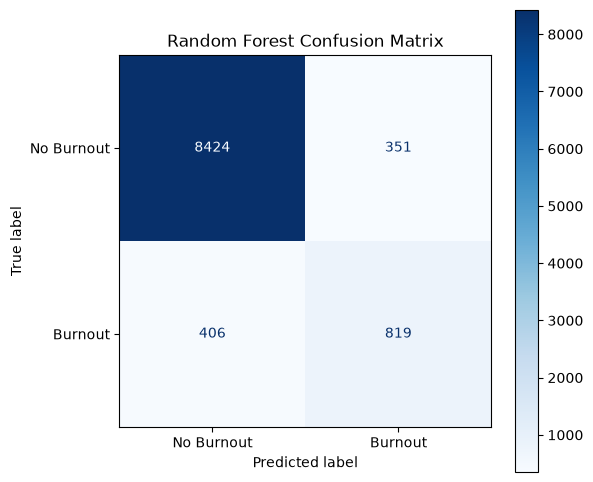

Random Forest confusion matrix saved as:
../outputs/notebook_random_forest_confusion_matrix.png


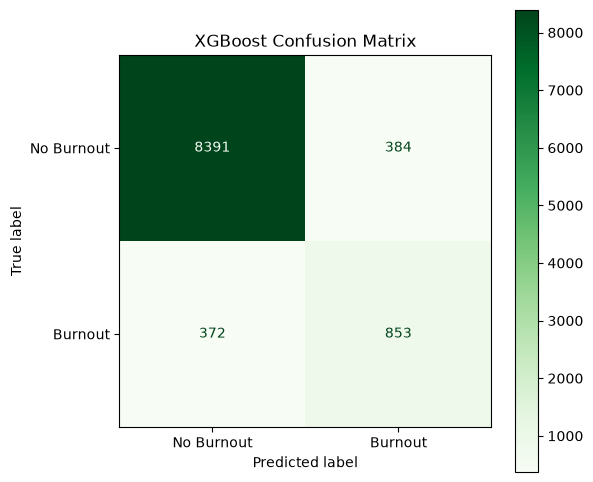

XGBoost confusion matrix saved as:
../outputs/notebook_xgboost_confusion_matrix.png


In [23]:
%matplotlib inline

import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create outputs folder
os.makedirs("../outputs", exist_ok=True)

# -----------------------------
# Random Forest Confusion Matrix
# -----------------------------
fig, ax = plt.subplots(figsize=(6, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["No Burnout", "Burnout"],
    values_format="d",
    cmap="Blues",
    ax=ax
)

plt.title("Random Forest Confusion Matrix")

# Save without overwriting your original project output
plt.savefig(
    "../outputs/notebook_random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

# Show inside notebook
plt.show()

# Close figure
plt.close()

print("Random Forest confusion matrix saved as:")
print("../outputs/notebook_random_forest_confusion_matrix.png")


# -----------------------------
# XGBoost Confusion Matrix
# -----------------------------
fig, ax = plt.subplots(figsize=(6, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred,
    display_labels=["No Burnout", "Burnout"],
    values_format="d",
    cmap="Greens",
    ax=ax
)

plt.title("XGBoost Confusion Matrix")

# Save without overwriting your original project output
plt.savefig(
    "../outputs/notebook_xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

# Show inside notebook
plt.show()

# Close figure
plt.close()

print("XGBoost confusion matrix saved as:")
print("../outputs/notebook_xgboost_confusion_matrix.png")

## 13. ROC Curve Comparison

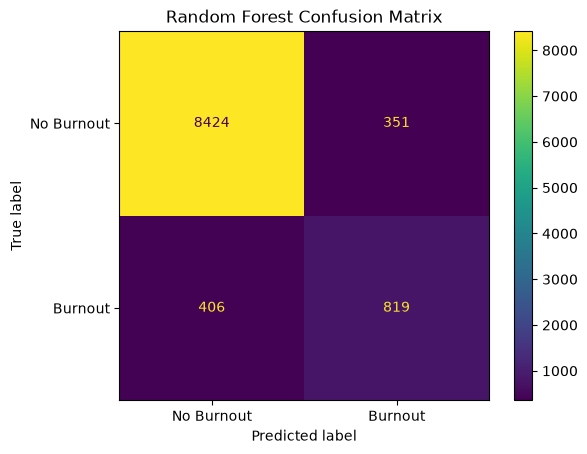

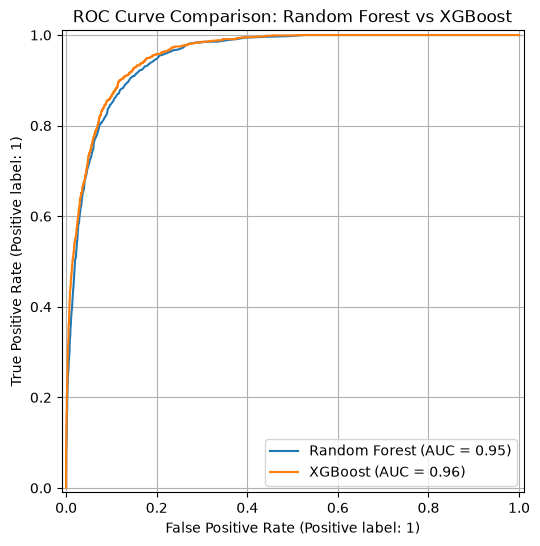

ROC curve saved successfully:
../outputs/notebook_roc_curve_comparison.png


In [21]:
%matplotlib inline

import os
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Create outputs folder safely
os.makedirs("../outputs", exist_ok=True)

# Create figure
fig, ax = plt.subplots(figsize=(8, 6))

# Random Forest ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    rf_prob,
    ax=ax,
    name="Random Forest"
)

# XGBoost ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    xgb_prob,
    ax=ax,
    name="XGBoost"
)

# Plot formatting
ax.set_title("ROC Curve Comparison: Random Forest vs XGBoost")
ax.grid(True)

# Save safely with notebook-specific filename
plt.savefig(
    "../outputs/notebook_roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

# Show inside notebook
plt.show()

# Close after displaying
plt.close()

print("ROC curve saved successfully:")
print("../outputs/notebook_roc_curve_comparison.png")

## 14. Feature Importance

In [17]:
rf_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

xgb_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

rf_importance.head(10), xgb_importance.head(10)

(                Feature  Importance
 15         stress_level    0.272219
 17     depression_score    0.129693
 16        anxiety_score    0.089204
 2   work_hours_per_week    0.080157
 8     work_life_balance    0.074512
 7       manager_support    0.036429
 14          has_therapy    0.033393
 3        overtime_hours    0.018999
 34     work_mode_Hybrid    0.017887
 19        gender_Female    0.015719,
                        Feature  Importance
 15                stress_level    0.175017
 14                 has_therapy    0.090430
 34            work_mode_Hybrid    0.063788
 33        company_size_Startup    0.059494
 20                 gender_Male    0.057091
 36            work_mode_Remote    0.051366
 30          company_size_Large    0.048613
 31            company_size_MNC    0.045845
 32       company_size_Mid-size    0.045576
 29  job_role_Software Engineer    0.041169)

## 15. SHAP Explainability

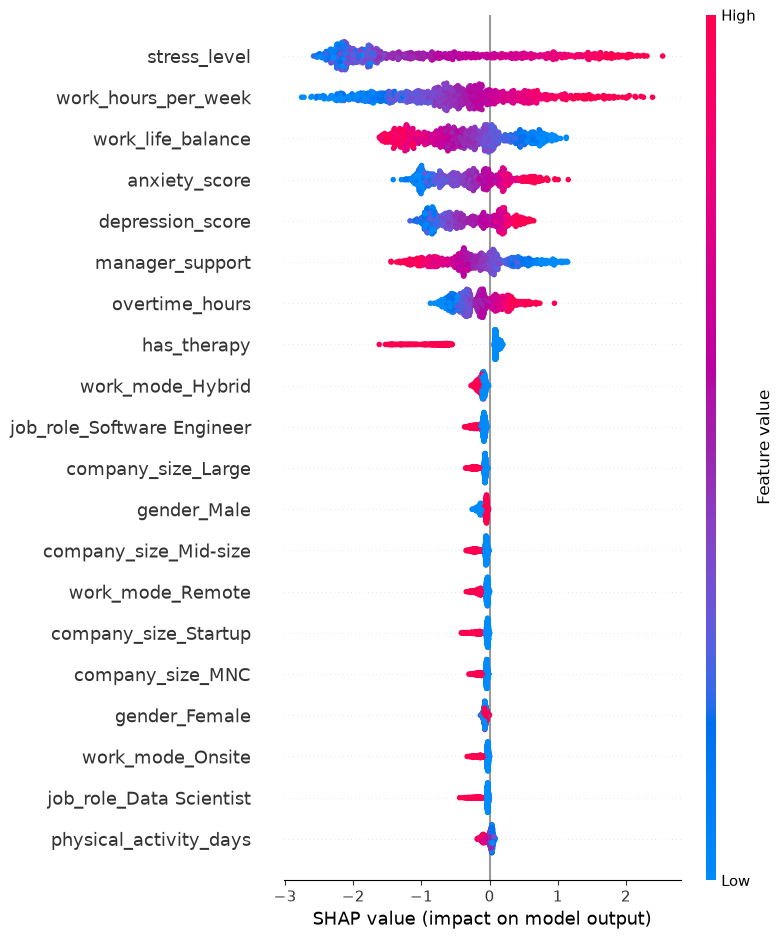

SHAP Summary Plot
Displayed successfully inside notebook.
Saved as:
../outputs/notebook_shap_summary_plot.png


In [22]:
%matplotlib inline

import os
import shap
import matplotlib.pyplot as plt

# Create outputs folder
os.makedirs("../outputs", exist_ok=True)

# Select a sample for SHAP analysis
X_sample = X_test_encoded.sample(
    n=min(1000, len(X_test_encoded)),
    random_state=42
)

# Create SHAP explainer
explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_sample)

# Handle binary classification output
if len(shap_values.values.shape) == 3:
    shap_values_binary = shap_values[:, :, 1]
else:
    shap_values_binary = shap_values

# Create a new figure
plt.figure(figsize=(10, 6))

# Generate SHAP Summary Plot
shap.summary_plot(
    shap_values_binary,
    X_sample,
    show=False
)

# Save without overwriting your original project output
plt.savefig(
    "../outputs/notebook_shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)

# Display inside the notebook
plt.show()

# Close the figure
plt.close()

print("=" * 60)
print("SHAP Summary Plot")
print("=" * 60)
print("Displayed successfully inside notebook.")
print("Saved as:")
print("../outputs/notebook_shap_summary_plot.png")

## 16. Feature Engineering Experiment

In [19]:
df_fe = df_50k.copy()

df_fe["mental_health_index"] = (
    df_fe["stress_level"] + df_fe["anxiety_score"] + df_fe["depression_score"]
) / 3

df_fe["workload_index"] = (
    df_fe["work_hours_per_week"] + df_fe["overtime_hours"]
)

df_fe["work_life_support_index"] = (
    df_fe["work_life_balance"] + df_fe["manager_support"]
) / 2

df_fe["lifestyle_index"] = (
    df_fe["sleep_hours"] + df_fe["physical_activity_days"]
) / 2

df_fe["screen_workload_interaction"] = (
    df_fe["screen_time_hours"] * df_fe["work_hours_per_week"]
)

print("Feature engineered shape:", df_fe.shape)
df_fe.head()

Feature engineered shape: (50000, 29)


,age,gender,job_role,experience_years,company_size,work_mode,work_hours_per_week,overtime_hours,meetings_per_day,deadlines_missed,...,stress_level,anxiety_score,depression_score,seeks_professional_help,target,mental_health_index,workload_index,work_life_support_index,lifestyle_index,screen_workload_interaction
0,29,Female,Product Manager,6.0,Startup,Remote,57.0,2.0,0.0,2,...,6.1,4.5,1.8,0,0,4.133333,59.0,5.45,4.65,444.6
1,37,Male,Data Scientist,7.8,Large,Remote,37.0,5.0,2.0,4,...,5.3,2.3,4.1,0,0,3.900000,42.0,4.75,5.35,270.1
2,34,Female,Backend Developer,5.4,Large,Hybrid,44.0,3.0,6.0,4,...,6.0,3.4,4.4,0,0,4.600000,47.0,2.30,4.80,255.2
3,36,Female,Frontend Developer,3.6,Mid-size,Hybrid,41.0,6.0,3.0,0,...,5.9,6.8,3.0,1,0,5.233333,47.0,5.20,2.45,479.7
4,52,Male,QA Engineer,1.7,Large,Remote,51.0,10.0,3.0,4,...,7.1,4.2,3.4,0,1,4.900000,61.0,3.30,5.15,392.7


## 17. Conclusion

The complete machine learning pipeline was implemented successfully. The baseline experiment selected XGBoost as the best model, while the feature-engineered experiment showed improvement in F1 score. SMOTE was applied only to the training data to avoid data leakage, and SHAP was used to explain model predictions.

## Feature Engineering Experiment: Model Behaviour Comparison

In [ ]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# =========================
# 1. Create engineered dataset
# =========================

df_fe = df_50k.copy()

df_fe["mental_health_index"] = (
    df_fe["stress_level"] +
    df_fe["anxiety_score"] +
    df_fe["depression_score"]
) / 3

df_fe["workload_index"] = (
    df_fe["work_hours_per_week"] +
    df_fe["overtime_hours"]
)

df_fe["work_life_support_index"] = (
    df_fe["work_life_balance"] +
    df_fe["manager_support"]
) / 2

df_fe["lifestyle_index"] = (
    df_fe["sleep_hours"] +
    df_fe["physical_activity_days"]
) / 2

df_fe["screen_workload_interaction"] = (
    df_fe["screen_time_hours"] *
    df_fe["work_hours_per_week"]
)

print("Feature engineered dataset shape:", df_fe.shape)

# =========================
# 2. Split data
# =========================

X_fe = df_fe.drop(columns=["target"])
y_fe = df_fe["target"]

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.20,
    random_state=42,
    stratify=y_fe
)

print("X_train_fe:", X_train_fe.shape)
print("X_test_fe:", X_test_fe.shape)

# =========================
# 3. One-Hot Encoding
# =========================

categorical_cols_fe = X_train_fe.select_dtypes(
    include=["object", "string"]
).columns.tolist()

encoder_fe = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_fe_encoded_array = encoder_fe.fit_transform(
    X_train_fe[categorical_cols_fe]
)

X_test_fe_encoded_array = encoder_fe.transform(
    X_test_fe[categorical_cols_fe]
)

encoded_cols_fe = encoder_fe.get_feature_names_out(categorical_cols_fe)

X_train_fe_encoded_df = pd.DataFrame(
    X_train_fe_encoded_array,
    columns=encoded_cols_fe,
    index=X_train_fe.index
)

X_test_fe_encoded_df = pd.DataFrame(
    X_test_fe_encoded_array,
    columns=encoded_cols_fe,
    index=X_test_fe.index
)

X_train_fe_num = X_train_fe.drop(columns=categorical_cols_fe)
X_test_fe_num = X_test_fe.drop(columns=categorical_cols_fe)

X_train_fe_encoded = pd.concat(
    [X_train_fe_num, X_train_fe_encoded_df],
    axis=1
)

X_test_fe_encoded = pd.concat(
    [X_test_fe_num, X_test_fe_encoded_df],
    axis=1
)

print("Encoded FE train:", X_train_fe_encoded.shape)
print("Encoded FE test:", X_test_fe_encoded.shape)

# =========================
# 4. SMOTE on training only
# =========================

smote_fe = SMOTE(random_state=42)

X_train_fe_smote, y_train_fe_smote = smote_fe.fit_resample(
    X_train_fe_encoded,
    y_train_fe
)

print("Before SMOTE:")
print(y_train_fe.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_fe_smote).value_counts())

# =========================
# 5. Train Random Forest
# =========================

rf_fe = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_fe.fit(X_train_fe_smote, y_train_fe_smote)

rf_fe_pred = rf_fe.predict(X_test_fe_encoded)
rf_fe_prob = rf_fe.predict_proba(X_test_fe_encoded)[:, 1]

rf_fe_results = {
    "Model": "Random Forest FE",
    "Accuracy": accuracy_score(y_test_fe, rf_fe_pred),
    "Precision": precision_score(y_test_fe, rf_fe_pred),
    "Recall": recall_score(y_test_fe, rf_fe_pred),
    "F1 Score": f1_score(y_test_fe, rf_fe_pred),
    "ROC-AUC": roc_auc_score(y_test_fe, rf_fe_prob)
}

# =========================
# 6. Train XGBoost
# =========================

xgb_fe = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_fe.fit(X_train_fe_smote, y_train_fe_smote)

xgb_fe_pred = xgb_fe.predict(X_test_fe_encoded)
xgb_fe_prob = xgb_fe.predict_proba(X_test_fe_encoded)[:, 1]

xgb_fe_results = {
    "Model": "XGBoost FE",
    "Accuracy": accuracy_score(y_test_fe, xgb_fe_pred),
    "Precision": precision_score(y_test_fe, xgb_fe_pred),
    "Recall": recall_score(y_test_fe, xgb_fe_pred),
    "F1 Score": f1_score(y_test_fe, xgb_fe_pred),
    "ROC-AUC": roc_auc_score(y_test_fe, xgb_fe_prob)
}

# =========================
# 7. Compare baseline vs feature engineering
# =========================

baseline_results = pd.DataFrame([
    rf_results,
    xgb_results
])

feature_engineering_results = pd.DataFrame([
    rf_fe_results,
    xgb_fe_results
])

comparison_all = pd.concat(
    [baseline_results, feature_engineering_results],
    axis=0
).reset_index(drop=True)

comparison_all